# Roundtable graph

In [1]:
import operator
from typing import Annotated, Any
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END

In [2]:
AUTHORS = ["marx", "bakunin", "mill"]


class State(TypedDict):
    question: str
    answer: str
    targets: list[str]    # which authors should answer (overwritten each step)
    needs_rag: bool       # decided by the Laya router
    state: Annotated[list, operator.add]  # append-only log


class ReturnNodeValue:
    """Placeholder node that just appends a message to the log."""

    def __init__(self, node_secret: str):
        self._value = node_secret

    def __call__(self, state: State) -> Any:
        print(f"Adding {self._value} to {state['state']}")
        return {"state": [self._value]}

In [ ]:
def target_router(state: State) -> dict:
    # TODO: replace with real logic (e.g. an LLM call) that picks the authors
    targets = list(AUTHORS)
    print(f"Targets selected: {targets}")
    return {"targets": targets, "state": }


def laya_router(state: State) -> dict:
    # TODO: replace with real logic that decides whether RAG is needed
    needs_rag = False
    print(f"Needs RAG: {needs_rag}")
    return {"needs_rag": needs_rag, "state": ["Decides whether the question needs RAG call"]}


def route_to_retrievers(state: State) -> list[str]:
    """Fan out to one retrieve node per selected author."""
    targets = [a for a in state["targets"] if a in AUTHORS]
    return [f"retrieve_{a}" for a in targets] or [END]


def make_retriever(author: str):
    def retrieve(state: State) -> dict:
        if state["needs_rag"]:
            msg = f"Made RAG call with author={author} metadata"
        else:
            msg = f"Skipped RAG for {author}"
        print(msg)
        return {"state": [msg]}
    return retrieve

In [9]:
builder = StateGraph(State)

builder.add_node("question", ReturnNodeValue("What's the purpose of life from your own perspective?"))
builder.add_node("target_router", target_router)
builder.add_node("laya_router", laya_router)

for author in AUTHORS:
    builder.add_node(f"retrieve_{author}", make_retriever(author))
    builder.add_node(f"{author}_agent", ReturnNodeValue(f"{author.capitalize()} Agent"))

builder.add_node("answers", ReturnNodeValue("Answer(s) Node"))

# Linear part
builder.add_edge(START, "question")
builder.add_edge("question", "target_router")
builder.add_edge("target_router", "laya_router")

# Conditional fan-out to the selected authors
builder.add_conditional_edges(
    "laya_router",
    route_to_retrievers,
    [f"retrieve_{a}" for a in AUTHORS] + [END],
)

# Each branch: retrieve -> agent -> answers (same length, so answers runs once)
for author in AUTHORS:
    builder.add_edge(f"retrieve_{author}", f"{author}_agent")
    builder.add_edge(f"{author}_agent", "answers")

builder.add_edge("answers", END)

graph = builder.compile()

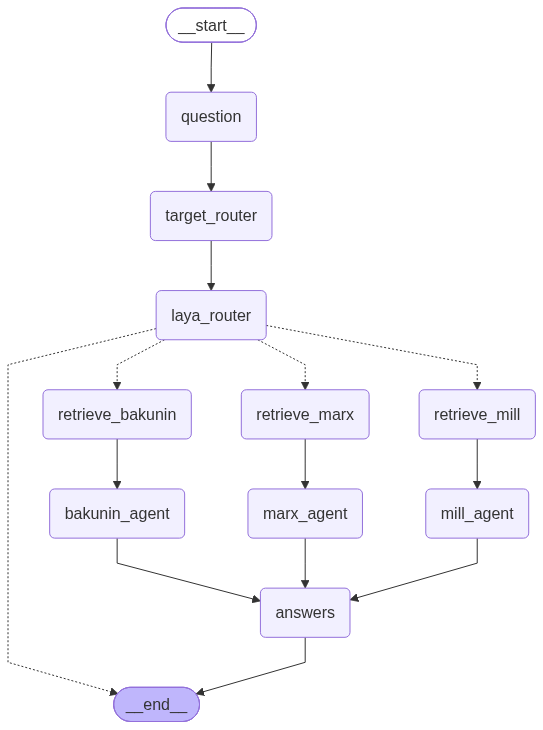

In [10]:
from IPython.display import Image, display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as e:
    # mermaid.ink unreachable or rejected the request: print the text instead.
    # Paste it into https://mermaid.live to view the diagram.
    print(f"Could not render PNG ({type(e).__name__}). Mermaid source:\n")
    print(graph.get_graph().draw_mermaid())

In [11]:
result = graph.invoke({
    "question": "Whats freedom from your own perspective?",
    "answer": "",
    "targets": [],
    "needs_rag": True,
    "state": [],
})
result

Adding What's the purpose of life from your own perspective? to []
Targets selected: ['marx', 'bakunin', 'mill']
Needs RAG: False
Skipped RAG for bakunin
Skipped RAG for marx
Skipped RAG for mill
Adding Bakunin Agent to ["What's the purpose of life from your own perspective?", 'Select the target(s) of the question', 'Decides whether the question needs RAG call', 'Skipped RAG for bakunin', 'Skipped RAG for marx', 'Skipped RAG for mill']
Adding Marx Agent to ["What's the purpose of life from your own perspective?", 'Select the target(s) of the question', 'Decides whether the question needs RAG call', 'Skipped RAG for bakunin', 'Skipped RAG for marx', 'Skipped RAG for mill']
Adding Mill Agent to ["What's the purpose of life from your own perspective?", 'Select the target(s) of the question', 'Decides whether the question needs RAG call', 'Skipped RAG for bakunin', 'Skipped RAG for marx', 'Skipped RAG for mill']
Adding Answer(s) Node to ["What's the purpose of life from your own perspectiv

{'question': 'Whats freedom from your own perspective?',
 'answer': '',
 'targets': ['marx', 'bakunin', 'mill'],
 'needs_rag': False,
 'state': ["What's the purpose of life from your own perspective?",
  'Select the target(s) of the question',
  'Decides whether the question needs RAG call',
  'Skipped RAG for bakunin',
  'Skipped RAG for marx',
  'Skipped RAG for mill',
  'Bakunin Agent',
  'Marx Agent',
  'Mill Agent',
  'Answer(s) Node']}